# Gom cụm khối u lành tính (benign) và ác tính (malignant) bằng k-Means

Để kiểm tra khối u, tổn thương trong ngực bệnh nhân có phải là ung thư hay không, người ta thực hiện phương pháp chọc hút tế bào bằng kim nhỏ (FNA). Tế bào lấy được sau đó được phân tích dưới kính hiển vi. Bảng dữ liệu (Breast Cancer Wisconsin - Diagnostic) được tính từ hình ảnh dưới kính hiển vi; các thuộc tính mô tả đặc tính của tế bào được phân tích.

Yêu cầu: dùng thuật toán gom cụm để gom nhóm các khối u lành tính (benign) hoặc ác tính (malignant).

> Bộ dữ liệu được lấy trực tiếp từ thư viện sklearn (`load_breast_cancer`), đây chính là bộ Breast Cancer Wisconsin (Diagnostic).

## 1. Đọc và khảo sát dữ liệu

In [7]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             adjusted_rand_score, silhouette_score)

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target   # 0 = malignant (ác tính), 1 = benign (lành tính)

print("Kích thước dữ liệu (số mẫu, số thuộc tính):", X.shape)
print("Các lớp:", list(data.target_names))
print("\nSố lượng mẫu theo từng lớp:")
print(pd.Series(y).map({0: 'malignant (ác tính)', 1: 'benign (lành tính)'}).value_counts())
print("\nSố giá trị bị thiếu:", X.isnull().sum().sum())
X.head()

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Kích thước dữ liệu (số mẫu, số thuộc tính): (569, 30)
Các lớp: [np.str_('malignant'), np.str_('benign')]

Số lượng mẫu theo từng lớp:
benign (lành tính)     357
malignant (ác tính)    212
Name: count, dtype: int64

Số giá trị bị thiếu: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Chuẩn hóa dữ liệu

Các thuộc tính có thang đo rất khác nhau (ví dụ `area` lên tới hàng nghìn, `smoothness` nhỏ hơn 1) nên cần chuẩn hóa trước khi gom cụm bằng k-Means, vì thuật toán dựa trên khoảng cách.

In [8]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Trung bình sau chuẩn hóa (xấp xỉ 0):", np.round(X_scaled.mean(), 4))
print("Độ lệch chuẩn sau chuẩn hóa (xấp xỉ 1):", np.round(X_scaled.std(), 4))

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Trung bình sau chuẩn hóa (xấp xỉ 0): -0.0
Độ lệch chuẩn sau chuẩn hóa (xấp xỉ 1): 1.0


## 3. Chọn số cụm (phương pháp Elbow và Silhouette)

Họ và tên: Lê Quốc Trung - MSSV: 6451071082


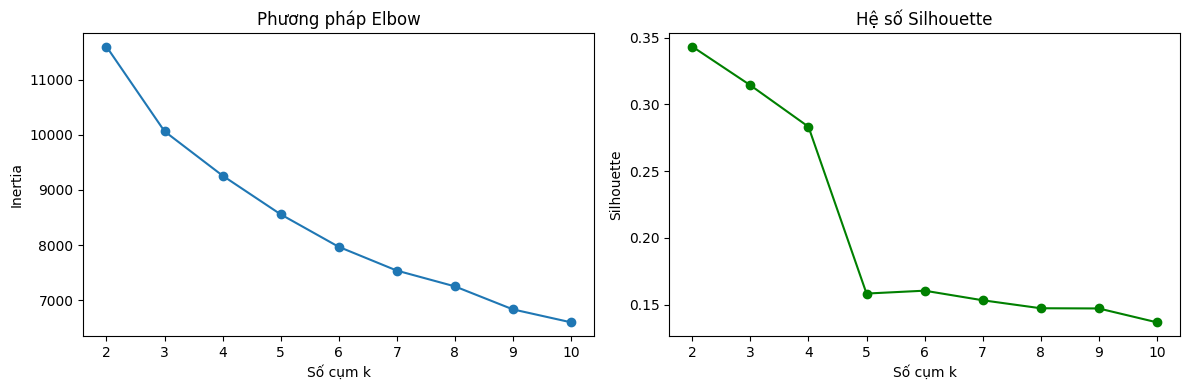

Bài toán có 2 nhóm cần phân biệt (lành tính / ác tính) nên chọn k = 2.


In [9]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertias, marker='o')
ax[0].set_title('Phương pháp Elbow'); ax[0].set_xlabel('Số cụm k'); ax[0].set_ylabel('Inertia')
ax[1].plot(list(ks), sils, marker='o', color='green')
ax[1].set_title('Hệ số Silhouette'); ax[1].set_xlabel('Số cụm k'); ax[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.show()
print("Bài toán có 2 nhóm cần phân biệt (lành tính / ác tính) nên chọn k = 2.")

## 4. Gom cụm bằng k-Means với k = 2

In [10]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

print("Số mẫu trong từng cụm:")
for c, n in zip(*np.unique(clusters, return_counts=True)):
    print(f"  Cụm {c}: {n} mẫu")
print("Silhouette:", round(silhouette_score(X_scaled, clusters), 4))

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Số mẫu trong từng cụm:
  Cụm 0: 375 mẫu
  Cụm 1: 194 mẫu
Silhouette: 0.3434


## 5. So sánh kết quả gom cụm với chẩn đoán thật (benign / malignant)

k-Means chỉ đánh số cụm 0, 1 một cách tùy ý, nên cần ghép mỗi cụm với lớp thật chiếm đa số trong cụm đó.

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Độ chính xác (accuracy): 0.9051
Adjusted Rand Index   : 0.6536

Báo cáo phân loại (precision, recall, f1-score):
                     precision    recall  f1-score   support

malignant (ác tính)       0.91      0.83      0.87       212
 benign (lành tính)       0.90      0.95      0.93       357

           accuracy                           0.91       569
          macro avg       0.91      0.89      0.90       569
       weighted avg       0.91      0.91      0.90       569



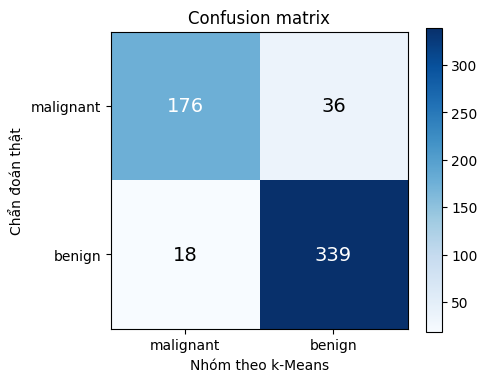

In [11]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
# Hai cách ghép nhãn có thể có: giữ nguyên hoặc đảo; chọn cách cho accuracy cao hơn
acc_giu = accuracy_score(y, clusters)
acc_dao = accuracy_score(y, 1 - clusters)
y_pred = clusters if acc_giu >= acc_dao else 1 - clusters

print(f"Độ chính xác (accuracy): {accuracy_score(y, y_pred):.4f}")
print(f"Adjusted Rand Index   : {adjusted_rand_score(y, clusters):.4f}")

print("\nBáo cáo phân loại (precision, recall, f1-score):")
print(classification_report(y, y_pred, target_names=['malignant (ác tính)', 'benign (lành tính)']))

cm = confusion_matrix(y, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues')
names = ['malignant', 'benign']
ax.set_xticks([0, 1]); ax.set_xticklabels(names)
ax.set_yticks([0, 1]); ax.set_yticklabels(names)
ax.set_xlabel('Nhóm theo k-Means'); ax.set_ylabel('Chẩn đoán thật')
ax.set_title('Confusion matrix')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)
plt.colorbar(im)
plt.tight_layout()
plt.show()

## 6. Trực quan hóa kết quả gom cụm (giảm về 2 chiều bằng PCA)

Họ và tên: Lê Quốc Trung - MSSV: 6451071082


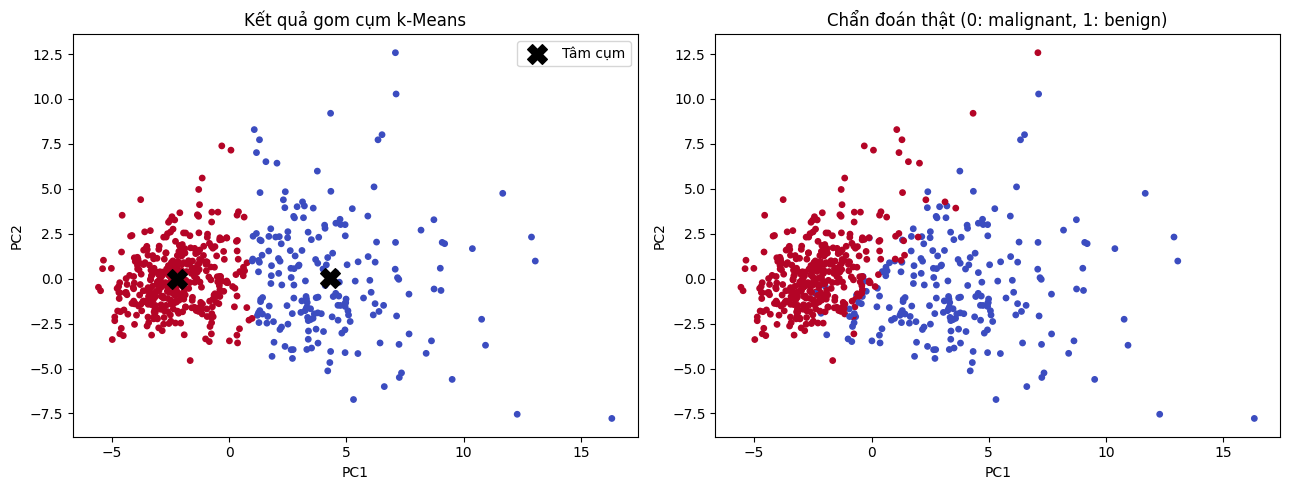

Phương sai giải thích bởi 2 thành phần chính: 0.6324


In [12]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)
centers_2d = pca.transform(kmeans.cluster_centers_)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(X_2d[:, 0], X_2d[:, 1], c=y_pred, cmap='coolwarm', s=15)
ax[0].scatter(centers_2d[:, 0], centers_2d[:, 1], c='black', marker='X', s=200, label='Tâm cụm')
ax[0].set_title('Kết quả gom cụm k-Means'); ax[0].legend()
ax[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap='coolwarm', s=15)
ax[1].set_title('Chẩn đoán thật (0: malignant, 1: benign)')
for a in ax:
    a.set_xlabel('PC1'); a.set_ylabel('PC2')
plt.tight_layout()
plt.show()
print("Phương sai giải thích bởi 2 thành phần chính:", np.round(pca.explained_variance_ratio_.sum(), 4))

### Nhận xét

- Sau khi chuẩn hóa, k-Means với k = 2 tách được dữ liệu thành hai nhóm tương ứng khá tốt với hai loại khối u lành tính và ác tính, dù thuật toán không hề được cung cấp nhãn.
- Phần sai lệch chủ yếu nằm ở các mẫu nằm gần ranh giới giữa hai nhóm (xem confusion matrix và biểu đồ PCA).
- Trong y tế, bỏ sót khối u ác tính (nhóm ác tính bị xếp nhầm vào cụm lành tính) nghiêm trọng hơn nhầm ngược lại, nên cần chú ý chỉ số recall của lớp malignant.